# UPI Fraud Detection — Model Training & Testing

**Hackathon:** KLU + Path-3 ML-02 — Real-Time UPI / Digital Payment Fraud Detection  
**Dataset:** `upi_transactions 2024.csv`  
**Target:** `fraud_flag` (0 = genuine, 1 = fraud)

## What this notebook does
1. Loads and validates the UPI transaction dataset.
2. Creates timestamp-based features and removes identifier / potential leakage fields.
3. Splits data into training, validation and final test sets using stratification.
4. Trains and compares:
   - Logistic Regression with class weights
   - Random Forest with class weights
   - Extra Trees with class weights
   - Logistic Regression with SMOTE (if `imbalanced-learn` is installed)
   - XGBoost (if installed)
5. Selects a model using **validation PR-AUC**, not accuracy.
6. Tunes a probability threshold on the validation set using editable business-cost assumptions.
7. Evaluates the selected model once on the untouched test set.
8. Exports the trained pipeline and metadata for later full-stack integration.

> **Leakage safeguards:** `transaction id` is an identifier and is excluded. `transaction_status` is excluded from the initial real-time model because it may be assigned after payment processing or fraud screening. `fraud_flag` is the target and is never an input. Resampling, when used, happens inside the training pipeline only.
>
> **Important:** This notebook uses a stratified random split to make sure the rare fraud class appears in each split. If the organisers provide a reliable chronological evaluation protocol, use a time-based split as an additional robustness check. Results on this simulated dataset should not be presented as proof of real-world UPI fraud behaviour.


## 1. Install / import dependencies

If running locally, uncomment the pip command if required. For SMOTE and XGBoost, install the optional packages separately.


In [1]:
# Uncomment if packages are missing:
# %pip install pandas numpy matplotlib seaborn scikit-learn joblib
# %pip install imbalanced-learn
# %pip install xgboost

import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    average_precision_score, roc_auc_score, confusion_matrix,
    classification_report, precision_recall_curve
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

try:
    from imblearn.pipeline import Pipeline as ImbPipeline
    from imblearn.over_sampling import SMOTE
    IMBLEARN_AVAILABLE = True
except ImportError:
    IMBLEARN_AVAILABLE = False
    print("imbalanced-learn not installed: SMOTE model will be skipped.")

try:
    from xgboost import XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("xgboost not installed: XGBoost model will be skipped.")


## 2. Load the dataset

Place `upi_transactions 2024.csv` in the same folder as this notebook, or change `DATA_PATH`.


In [2]:
DATA_PATH = Path("upi_transactions 2024.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}\n"
        "Put the CSV beside this notebook or update DATA_PATH."
    )

raw_df = pd.read_csv(DATA_PATH)
df = raw_df.copy()

print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns")
display(df.head())
print("\nData types:")
display(df.dtypes.to_frame("dtype"))


Shape: 250,000 rows × 17 columns


,transaction id,timestamp,transaction type,merchant_category,amount (INR),transaction_status,sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,fraud_flag,hour_of_day,day_of_week,is_weekend
0,TXN0000000001,2024-10-08 15:17:28,P2P,Entertainment,868,SUCCESS,26-35,18-25,Delhi,Axis,SBI,Android,4G,0,15,Tuesday,0
1,TXN0000000002,2024-04-11 06:56:00,P2M,Grocery,1011,SUCCESS,26-35,26-35,Uttar Pradesh,ICICI,Axis,iOS,4G,0,6,Thursday,0
2,TXN0000000003,2024-04-02 13:27:18,P2P,Grocery,477,SUCCESS,26-35,36-45,Karnataka,Yes Bank,PNB,Android,4G,0,13,Tuesday,0
3,TXN0000000004,2024-01-07 10:09:17,P2P,Fuel,2784,SUCCESS,26-35,26-35,Delhi,ICICI,PNB,Android,5G,0,10,Sunday,1
4,TXN0000000005,2024-01-23 19:04:23,P2P,Shopping,990,SUCCESS,26-35,18-25,Delhi,Axis,Yes Bank,iOS,WiFi,0,19,Tuesday,0



Data types:


,dtype
transaction id,str
timestamp,str
transaction type,str
merchant_category,str
amount (INR),int64
transaction_status,str
sender_age_group,str
receiver_age_group,str
sender_state,str
sender_bank,str


## 3. Validate and clean essential fields

This is a conservative modelling preparation step. It removes exact duplicate rows and records that cannot be used for supervised learning because the target, timestamp, transaction ID or positive amount is invalid. Valid high amounts are retained.


In [3]:
required = [
    "transaction id", "timestamp", "transaction type", "merchant_category",
    "amount (INR)", "transaction_status", "sender_age_group",
    "receiver_age_group", "sender_state", "sender_bank", "receiver_bank",
    "device_type", "network_type", "fraud_flag", "hour_of_day",
    "day_of_week", "is_weekend"
]
missing_cols = sorted(set(required) - set(df.columns))
if missing_cols:
    raise ValueError(f"Missing expected columns: {missing_cols}")

before_rows = len(df)
df = df.drop_duplicates().copy()
duplicates_removed = before_rows - len(df)

# Normalize strings and parse typed fields.
for col in df.select_dtypes(include=["object"]).columns:
    df[col] = df[col].astype("string").str.strip().replace("", pd.NA)

df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["amount (INR)"] = pd.to_numeric(df["amount (INR)"], errors="coerce")
df["fraud_flag"] = pd.to_numeric(df["fraud_flag"], errors="coerce")

valid = (
    df["transaction id"].notna()
    & df["timestamp"].notna()
    & df["amount (INR)"].gt(0)
    & df["fraud_flag"].isin([0, 1])
)
invalid_removed = int((~valid).sum())
df = df.loc[valid].copy()
df["fraud_flag"] = df["fraud_flag"].astype("int8")

# Duplicate IDs are inspected, not silently discarded.
duplicate_id_count = int(df["transaction id"].duplicated().sum())

quality_summary = pd.DataFrame({
    "item": [
        "Original rows", "Exact duplicate rows removed", "Invalid essential rows removed",
        "Rows retained", "Missing cells retained", "Duplicate transaction IDs retained",
        "Genuine transactions", "Fraud transactions"
    ],
    "value": [
        len(raw_df), duplicates_removed, invalid_removed, len(df),
        int(df.isna().sum().sum()), duplicate_id_count,
        int((df["fraud_flag"] == 0).sum()), int((df["fraud_flag"] == 1).sum())
    ]
})
display(quality_summary)

if duplicate_id_count:
    print("Warning: duplicate transaction IDs exist. Inspect them before final submission.")
    display(df[df["transaction id"].duplicated(keep=False)].head(10))


,item,value
0,Original rows,250000
1,Exact duplicate rows removed,0
2,Invalid essential rows removed,0
3,Rows retained,250000
4,Missing cells retained,0
5,Duplicate transaction IDs retained,0
6,Genuine transactions,249520
7,Fraud transactions,480


## 4. Feature engineering and leakage control

Time features are derived from `timestamp`. The original `hour_of_day`, `day_of_week` and `is_weekend` fields are not used as model inputs; derived timestamp features are used consistently.

`transaction_status` is excluded because the model is intended to score a transaction at decision time. If the data dictionary confirms that status is available before the decision, this exclusion can be reconsidered with a leakage audit.


In [4]:
df["txn_hour"] = df["timestamp"].dt.hour
df["txn_day_of_week"] = df["timestamp"].dt.dayofweek.astype(str)
df["txn_month"] = df["timestamp"].dt.month.astype(str)
df["txn_is_weekend"] = (df["timestamp"].dt.dayofweek >= 5).astype("int8")

# Optional cyclic time features help represent the circular nature of hours.
df["hour_sin"] = np.sin(2 * np.pi * df["txn_hour"] / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["txn_hour"] / 24)

TARGET = "fraud_flag"
DROP_FROM_FEATURES = [
    "transaction id",       # unique identifier
    "timestamp",            # raw timestamp replaced by derived features
    "transaction_status",   # potential post-outcome leakage
    "fraud_flag",           # target
    "hour_of_day",          # replaced by timestamp-derived features
    "day_of_week",          # replaced by timestamp-derived features
    "is_weekend"             # replaced by timestamp-derived features
]

X = df.drop(columns=DROP_FROM_FEATURES, errors="ignore")
y = df[TARGET].astype(int)

# Use numeric/categorical column lists for preprocessing.
numeric_features = X.select_dtypes(include=["number", "bool"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "string", "category"]).columns.tolist()

print("Model input columns:")
print(X.columns.tolist())
print("\nNumeric features:", numeric_features)
print("Categorical features:", categorical_features)
print(f"Fraud rate: {y.mean():.4%}")


Model input columns:
['transaction type', 'merchant_category', 'amount (INR)', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'txn_hour', 'txn_day_of_week', 'txn_month', 'txn_is_weekend', 'hour_sin', 'hour_cos']

Numeric features: ['amount (INR)', 'txn_hour', 'txn_is_weekend', 'hour_sin', 'hour_cos']
Categorical features: ['transaction type', 'merchant_category', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'txn_day_of_week', 'txn_month']
Fraud rate: 0.1920%


## 5. Train / validation / test split

We use 70% training, 15% validation and 15% final testing. The validation set is used for model selection and threshold tuning. The test set remains untouched until final evaluation.


In [5]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "split": ["Train", "Validation", "Test"],
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "frauds": [int(y_train.sum()), int(y_valid.sum()), int(y_test.sum())],
    "fraud_rate_percent": [y_train.mean()*100, y_valid.mean()*100, y_test.mean()*100]
})
display(split_summary)

assert set(X_train.index).isdisjoint(set(X_valid.index))
assert set(X_train.index).isdisjoint(set(X_test.index))
assert set(X_valid.index).isdisjoint(set(X_test.index))


,split,rows,frauds,fraud_rate_percent
0,Train,175000,336,0.192
1,Validation,37500,72,0.192
2,Test,37500,72,0.192


## 6. Build preprocessing pipelines

Numerical values are median-imputed and standardized. Categorical values are mode-imputed and one-hot encoded. All preprocessing is fitted using training data only because it is inside each model pipeline.


In [6]:
def make_preprocessor():
    numeric_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ])
    categorical_pipe = Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="ignore"))
    ])
    return ColumnTransformer(
        transformers=[
            ("num", numeric_pipe, numeric_features),
            ("cat", categorical_pipe, categorical_features)
        ],
        remainder="drop"
    )

def make_standard_pipeline(classifier):
    return Pipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("model", classifier)
    ])


## 7. Train supervised models

Models are compared using validation PR-AUC (average precision), which is more informative than accuracy for a rare fraud class. Training time is recorded. The optional XGBoost and SMOTE models are included only when their packages are installed.


In [7]:
models = {
    "Logistic Regression (class_weight)": make_standard_pipeline(
        LogisticRegression(
            class_weight="balanced", max_iter=1500,
            solver="liblinear", random_state=RANDOM_STATE
        )
    ),
    "Random Forest (class_weight)": make_standard_pipeline(
        RandomForestClassifier(
            n_estimators=180, max_depth=16, min_samples_leaf=3,
            class_weight="balanced_subsample",
            n_jobs=-1, random_state=RANDOM_STATE
        )
    ),
    "Extra Trees (class_weight)": make_standard_pipeline(
        ExtraTreesClassifier(
            n_estimators=180, max_depth=16, min_samples_leaf=3,
            class_weight="balanced",
            n_jobs=-1, random_state=RANDOM_STATE
        )
    )
}

if XGBOOST_AVAILABLE:
    # scale_pos_weight is calculated from the training labels only.
    scale_pos_weight = (y_train == 0).sum() / max((y_train == 1).sum(), 1)
    models["XGBoost"] = make_standard_pipeline(
        XGBClassifier(
            n_estimators=250, max_depth=5, learning_rate=0.05,
            subsample=0.85, colsample_bytree=0.85,
            scale_pos_weight=scale_pos_weight,
            eval_metric="aucpr", tree_method="hist",
            random_state=RANDOM_STATE, n_jobs=-1
        )
    )

trained_models = {}
validation_rows = []

for name, model in models.items():
    print(f"Training {name} ...")
    start = time.time()
    model.fit(X_train, y_train)
    elapsed = time.time() - start

    valid_scores = model.predict_proba(X_valid)[:, 1]
    trained_models[name] = model

    validation_rows.append({
        "model": name,
        "validation_PR_AUC": average_precision_score(y_valid, valid_scores),
        "validation_ROC_AUC": roc_auc_score(y_valid, valid_scores),
        "training_seconds": round(elapsed, 2)
    })

# Optional SMOTE model. SMOTE runs only after preprocessing and only on X_train.
if IMBLEARN_AVAILABLE:
    smote_pipeline = ImbPipeline(steps=[
        ("preprocess", make_preprocessor()),
        ("smote", SMOTE(random_state=RANDOM_STATE, sampling_strategy=0.5)),
        ("model", LogisticRegression(max_iter=1500, solver="liblinear", random_state=RANDOM_STATE))
    ])
    print("Training Logistic Regression (SMOTE) ...")
    start = time.time()
    smote_pipeline.fit(X_train, y_train)
    elapsed = time.time() - start
    trained_models["Logistic Regression (SMOTE)"] = smote_pipeline
    smote_scores = smote_pipeline.predict_proba(X_valid)[:, 1]
    validation_rows.append({
        "model": "Logistic Regression (SMOTE)",
        "validation_PR_AUC": average_precision_score(y_valid, smote_scores),
        "validation_ROC_AUC": roc_auc_score(y_valid, smote_scores),
        "training_seconds": round(elapsed, 2)
    })

validation_results = pd.DataFrame(validation_rows).sort_values(
    "validation_PR_AUC", ascending=False
).reset_index(drop=True)

display(validation_results)


Training Logistic Regression (class_weight) ...
Training Random Forest (class_weight) ...
Training Extra Trees (class_weight) ...
Training XGBoost ...
Training Logistic Regression (SMOTE) ...


,model,validation_PR_AUC,validation_ROC_AUC,training_seconds
0,Extra Trees (class_weight),0.001985,0.474902,35.43
1,Random Forest (class_weight),0.001778,0.450915,27.74
2,XGBoost,0.001754,0.465286,4.58
3,Logistic Regression (class_weight),0.001750,0.461027,1.56
4,Logistic Regression (SMOTE),0.001688,0.443218,1.75


## 8. Compare validation precision-recall curves

The PR curve shows the trade-off between precision and recall across probability thresholds. A random-ranking baseline has expected average precision approximately equal to the fraud prevalence.


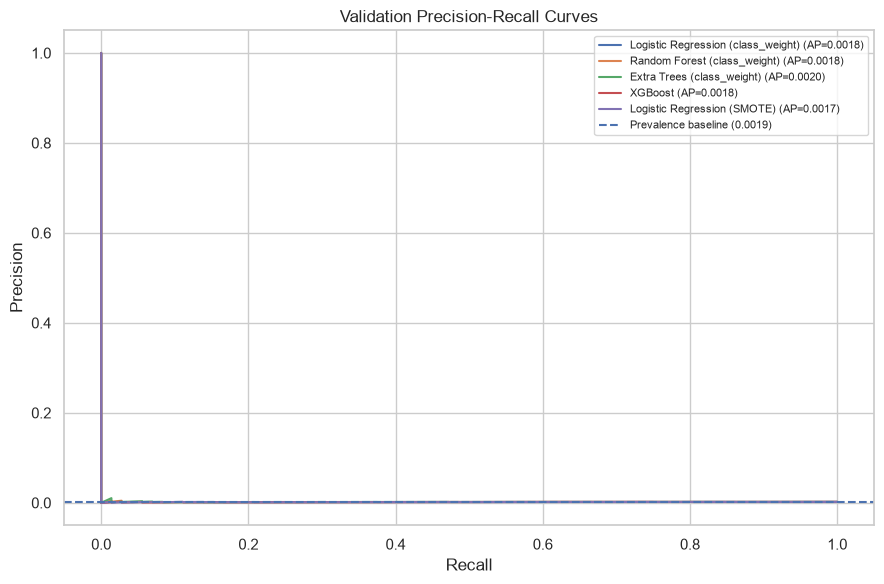

In [8]:
plt.figure(figsize=(9, 6))
for name, model in trained_models.items():
    scores = model.predict_proba(X_valid)[:, 1]
    precision, recall, _ = precision_recall_curve(y_valid, scores)
    ap = average_precision_score(y_valid, scores)
    plt.plot(recall, precision, label=f"{name} (AP={ap:.4f})")

baseline = y_valid.mean()
plt.axhline(baseline, linestyle="--", label=f"Prevalence baseline ({baseline:.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Validation Precision-Recall Curves")
plt.legend(loc="best", fontsize=8)
plt.tight_layout()
plt.show()


## 9. Select the candidate model

Select the model with the highest validation PR-AUC. Do not select based on test-set results. If two models are very close, prefer the simpler or faster model and consider expected cost and operational constraints.


In [9]:
best_model_name = validation_results.iloc[0]["model"]
best_model = trained_models[best_model_name]
valid_scores = best_model.predict_proba(X_valid)[:, 1]

print("Selected model:", best_model_name)
print("Validation PR-AUC:", round(average_precision_score(y_valid, valid_scores), 6))
print("Validation ROC-AUC:", round(roc_auc_score(y_valid, valid_scores), 6))


Selected model: Extra Trees (class_weight)
Validation PR-AUC: 0.001985
Validation ROC-AUC: 0.474902


## 10. Tune the decision threshold using business costs

Change the assumptions below to the organiser's official values when provided. The example values are **illustrative only**, not official bank costs.

Expected binary decision cost:
- False negative (missed fraud): `MISSED_FRAUD_COST`
- False positive (genuine transaction incorrectly blocked): `FALSE_BLOCK_COST`

Threshold selection uses validation data only. OTP is not modelled as a separate action in this binary cost calculation; a three-action approve / OTP / block policy should be calibrated separately once OTP cost and OTP success/residual-risk assumptions are known.


Validation cost-minimizing threshold: 0.5710
Validation estimated cost: ₹360,000.00


,value
threshold,0.571
TN,37428.000
FP,0.000
FN,72.000
TP,0.000
expected_cost,360000.000


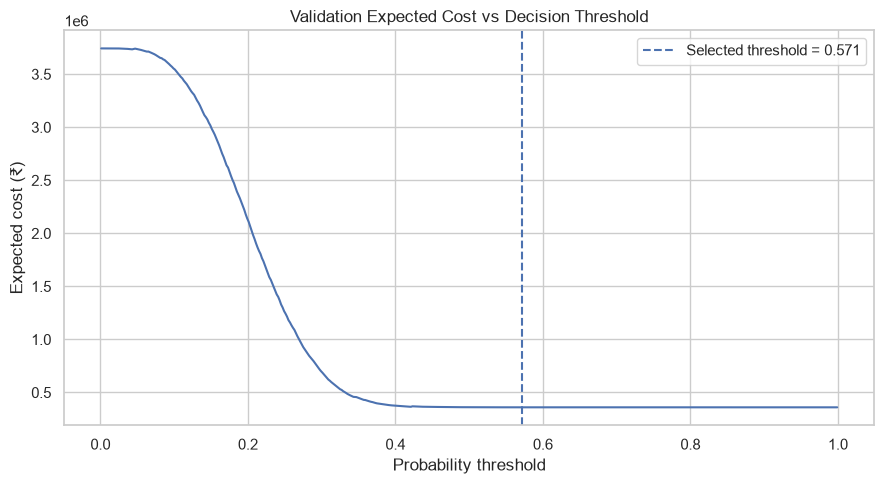

In [10]:
# EDIT THESE when the organisers provide official cost assumptions.
MISSED_FRAUD_COST = 5000.0   # illustrative ₹ per missed fraud
FALSE_BLOCK_COST = 100.0    # illustrative ₹ per genuine transaction blocked

thresholds = np.linspace(0.001, 0.999, 500)
cost_rows = []

for threshold in thresholds:
    pred = (valid_scores >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_valid, pred, labels=[0, 1]).ravel()
    total_cost = fn * MISSED_FRAUD_COST + fp * FALSE_BLOCK_COST
    cost_rows.append({
        "threshold": threshold, "TN": tn, "FP": fp,
        "FN": fn, "TP": tp, "expected_cost": total_cost
    })

cost_curve = pd.DataFrame(cost_rows)
best_cost_row = cost_curve.loc[cost_curve["expected_cost"].idxmin()]
BEST_THRESHOLD = float(best_cost_row["threshold"])

print(f"Validation cost-minimizing threshold: {BEST_THRESHOLD:.4f}")
print(f"Validation estimated cost: ₹{best_cost_row['expected_cost']:,.2f}")
display(best_cost_row.to_frame("value"))

plt.figure(figsize=(9, 5))
plt.plot(cost_curve["threshold"], cost_curve["expected_cost"])
plt.axvline(BEST_THRESHOLD, linestyle="--", label=f"Selected threshold = {BEST_THRESHOLD:.3f}")
plt.xlabel("Probability threshold")
plt.ylabel("Expected cost (₹)")
plt.title("Validation Expected Cost vs Decision Threshold")
plt.legend()
plt.tight_layout()
plt.show()


## 11. Evaluate the selected model on the untouched test set

The threshold was chosen using validation data. The final test set is now used once to estimate generalization performance.


In [11]:
test_scores = best_model.predict_proba(X_test)[:, 1]
test_predictions = (test_scores >= BEST_THRESHOLD).astype(int)

tn, fp, fn, tp = confusion_matrix(y_test, test_predictions, labels=[0, 1]).ravel()
test_cost = fn * MISSED_FRAUD_COST + fp * FALSE_BLOCK_COST

test_metrics = pd.DataFrame([{
    "model": best_model_name,
    "test_accuracy": accuracy_score(y_test, test_predictions),
    "test_precision": precision_score(y_test, test_predictions, zero_division=0),
    "test_recall": recall_score(y_test, test_predictions, zero_division=0),
    "test_F1": f1_score(y_test, test_predictions, zero_division=0),
    "test_PR_AUC": average_precision_score(y_test, test_scores),
    "test_ROC_AUC": roc_auc_score(y_test, test_scores),
    "threshold_from_validation": BEST_THRESHOLD,
    "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    "test_cost_under_assumptions_INR": test_cost
}])
display(test_metrics.T.rename(columns={0: "test result"}))

print("\nClassification report:")
print(classification_report(
    y_test, test_predictions,
    target_names=["Genuine", "Fraud"],
    zero_division=0
))


,test result
model,Extra Trees (class_weight)
test_accuracy,0.998053
test_precision,0.0
test_recall,0.0
test_F1,0.0
test_PR_AUC,0.001796
test_ROC_AUC,0.478852
threshold_from_validation,0.571
TN,37427
FP,1



Classification report:
              precision    recall  f1-score   support

     Genuine       1.00      1.00      1.00     37428
       Fraud       0.00      0.00      0.00        72

    accuracy                           1.00     37500
   macro avg       0.50      0.50      0.50     37500
weighted avg       1.00      1.00      1.00     37500



## 12. Confusion matrix and test-set precision-recall curve


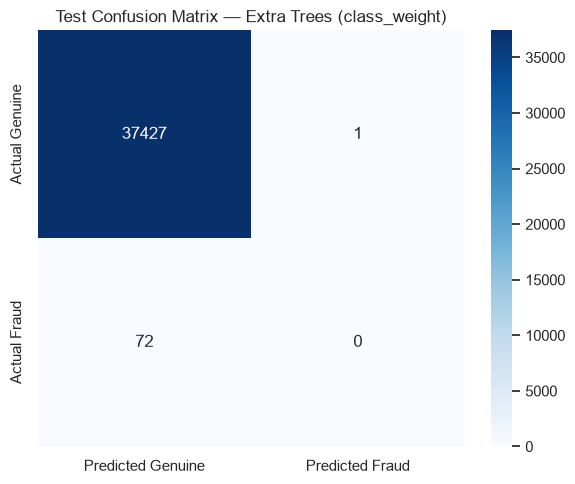

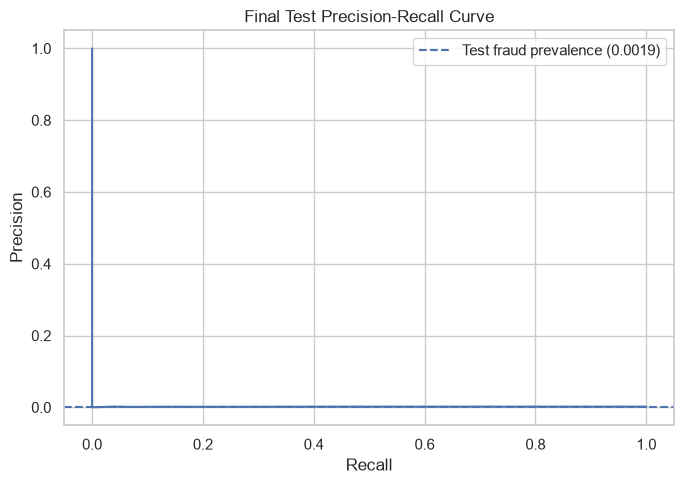

In [12]:
cm = confusion_matrix(y_test, test_predictions, labels=[0, 1])

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm, annot=True, fmt="d", cmap="Blues",
    xticklabels=["Predicted Genuine", "Predicted Fraud"],
    yticklabels=["Actual Genuine", "Actual Fraud"]
)
plt.title(f"Test Confusion Matrix — {best_model_name}")
plt.tight_layout()
plt.show()

test_precision_curve, test_recall_curve, _ = precision_recall_curve(y_test, test_scores)
plt.figure(figsize=(7, 5))
plt.plot(test_recall_curve, test_precision_curve)
plt.axhline(y_test.mean(), linestyle="--", label=f"Test fraud prevalence ({y_test.mean():.4f})")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final Test Precision-Recall Curve")
plt.legend()
plt.tight_layout()
plt.show()


## 13. Provisional three-level decision bands

This creates an initial score-to-action mapping for a demo:
- Approve: score below half of the selected binary threshold.
- Step-up OTP: score from half the threshold up to the threshold.
- Block: score at or above the selected binary threshold.

**This OTP band is provisional, not cost-optimized.** The organisers' OTP cost and the effectiveness of OTP verification are needed to optimize all three actions properly. Report the test counts in each band before using this policy operationally.


In [13]:
OTP_THRESHOLD = BEST_THRESHOLD * 0.5
BLOCK_THRESHOLD = BEST_THRESHOLD

def risk_decision(probability):
    if probability >= BLOCK_THRESHOLD:
        return "BLOCK"
    elif probability >= OTP_THRESHOLD:
        return "STEP_UP_OTP"
    return "APPROVE"

test_actions = pd.DataFrame({
    "actual_fraud": y_test.to_numpy(),
    "fraud_probability": test_scores,
    "decision": [risk_decision(p) for p in test_scores]
}, index=X_test.index)

band_summary = (
    test_actions.groupby("decision")
    .agg(
        transactions=("actual_fraud", "size"),
        actual_frauds=("actual_fraud", "sum")
    )
)
band_summary["genuine_transactions"] = band_summary["transactions"] - band_summary["actual_frauds"]
band_summary["fraud_rate_percent"] = (
    100 * band_summary["actual_frauds"] / band_summary["transactions"]
)
display(band_summary)
print(f"Approve below: {OTP_THRESHOLD:.4f}")
print(f"OTP from: {OTP_THRESHOLD:.4f} to below {BLOCK_THRESHOLD:.4f}")
print(f"Block at or above: {BLOCK_THRESHOLD:.4f}")


,transactions,actual_frauds,genuine_transactions,fraud_rate_percent
decision,,,,
APPROVE,32542,66,32476,0.202815
BLOCK,1,0,1,0.000000
STEP_UP_OTP,4957,6,4951,0.121041


Approve below: 0.2855
OTP from: 0.2855 to below 0.5710
Block at or above: 0.5710


## 14. Export model for full-stack integration

The exported `upi_fraud_model.joblib` contains the complete preprocessing + classifier pipeline. Your backend should load this file and pass a transaction as a dictionary/DataFrame using the feature names listed below.

The metadata JSON includes the selected model, input columns, threshold and illustrative cost assumptions. Keep the model and metadata versioned together.


In [14]:
# Export the trained pipeline.
MODEL_PATH = Path("upi_fraud_model.joblib")
METADATA_PATH = Path("upi_fraud_model_metadata.json")

joblib.dump(best_model, MODEL_PATH)

metadata = {
    "project": "UPI Real-Time Fraud Detection",
    "model_name": best_model_name,
    "target_column": TARGET,
    "positive_class": 1,
    "input_features": X.columns.tolist(),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "excluded_columns": DROP_FROM_FEATURES,
    "decision_threshold": BEST_THRESHOLD,
    "otp_threshold_provisional": OTP_THRESHOLD,
    "block_threshold": BLOCK_THRESHOLD,
    "threshold_method": "minimum validation expected cost for binary missed-fraud vs false-block costs",
    "missed_fraud_cost_inr_illustrative": MISSED_FRAUD_COST,
    "false_block_cost_inr_illustrative": FALSE_BLOCK_COST,
    "validation_pr_auc": float(average_precision_score(y_valid, valid_scores)),
    "test_pr_auc": float(average_precision_score(y_test, test_scores)),
    "test_recall": float(recall_score(y_test, test_predictions, zero_division=0)),
    "test_precision": float(precision_score(y_test, test_predictions, zero_division=0)),
    "random_state": RANDOM_STATE,
    "note": "transaction_status excluded as potential leakage; OTP band is provisional and not cost-optimized"
}

with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)

print(f"Saved model: {MODEL_PATH.resolve()}")
print(f"Saved metadata: {METADATA_PATH.resolve()}")
print("Model input features:")
print(X.columns.tolist())


Saved model: C:\Users\thula\Desktop\Hackathon_FraudDetection\Model\upi_fraud_model.joblib
Saved metadata: C:\Users\thula\Desktop\Hackathon_FraudDetection\Model\upi_fraud_model_metadata.json
Model input features:
['transaction type', 'merchant_category', 'amount (INR)', 'sender_age_group', 'receiver_age_group', 'sender_state', 'sender_bank', 'receiver_bank', 'device_type', 'network_type', 'txn_hour', 'txn_day_of_week', 'txn_month', 'txn_is_weekend', 'hour_sin', 'hour_cos']


## 15. Test the exported model with one transaction

This simulates what a backend API will do: load the saved pipeline, prepare a transaction with the same input feature names, get a fraud probability and map it to an action.

Use a real row from the test set for this smoke test. Do not use the transaction ID, timestamp, transaction status or target as input.


In [15]:
loaded_model = joblib.load(MODEL_PATH)

sample_transaction = X_test.iloc[[0]].copy()
sample_probability = float(loaded_model.predict_proba(sample_transaction)[:, 1][0])
sample_decision = risk_decision(sample_probability)

print("Sample transaction input:")
display(sample_transaction)
print(f"Fraud risk score: {sample_probability:.4%}")
print("Recommended action:", sample_decision)
print("Actual label (for offline test only):", int(y_test.loc[sample_transaction.index[0]]))


Sample transaction input:


,transaction type,merchant_category,amount (INR),sender_age_group,receiver_age_group,sender_state,sender_bank,receiver_bank,device_type,network_type,txn_hour,txn_day_of_week,txn_month,txn_is_weekend,hour_sin,hour_cos
151326,P2M,Grocery,1748,26-35,46-55,Karnataka,HDFC,SBI,iOS,5G,20,0,11,0,-0.866025,0.5


Fraud risk score: 22.1968%
Recommended action: APPROVE
Actual label (for offline test only): 0


## 16. Backend integration example (FastAPI)

This is a minimal example of loading the exported model. In your full-stack backend, validate request fields and types, then call `predict_proba`. Keep the model artifact and metadata file in the backend's model directory.

```python
import joblib
import pandas as pd
from fastapi import FastAPI
from pydantic import BaseModel

app = FastAPI()
model = joblib.load("upi_fraud_model.joblib")
metadata = ... # load upi_fraud_model_metadata.json

class Transaction(BaseModel):
    # Add one field for every item in metadata["input_features"].
    # Use the exact feature names and appropriate types.
    pass

@app.post("/predict")
def predict(transaction: dict):
    row = pd.DataFrame([transaction])
    expected = metadata["input_features"]
    row = row.reindex(columns=expected)
    probability = float(model.predict_proba(row)[0, 1])

    otp_threshold = metadata["otp_threshold_provisional"]
    block_threshold = metadata["block_threshold"]

    if probability >= block_threshold:
        decision = "BLOCK"
    elif probability >= otp_threshold:
        decision = "STEP_UP_OTP"
    else:
        decision = "APPROVE"

    return {
        "fraud_probability": probability,
        "risk_percent": round(probability * 100, 2),
        "decision": decision
    }
```

**Integration warning:** The API must receive the same feature fields and types used in training. `timestamp` is not an input in this saved pipeline; send the derived features (`txn_hour`, `txn_day_of_week`, `txn_month`, `txn_is_weekend`, `hour_sin`, `hour_cos`) along with the other feature columns. For a production-grade system, add strict request validation, authentication, monitoring, model versioning and a safe fallback if inference fails.


## 17. Final checklist

- [ ] Dataset loaded and validated.
- [ ] Identifier and potential leakage fields excluded.
- [ ] Stratified train / validation / test split created.
- [ ] Preprocessing fitted inside model pipelines.
- [ ] Class-weight models trained and compared.
- [ ] SMOTE used only inside the training pipeline (if installed).
- [ ] Model selected using validation PR-AUC.
- [ ] Threshold selected using validation costs.
- [ ] Final metrics reported on untouched test data.
- [ ] Confusion matrix and PR curve reviewed.
- [ ] Model and metadata exported for full-stack integration.

### Interpretation reminder
A low PR-AUC close to fraud prevalence means the model has limited ranking ability. Do not hide weak results or claim the model is production-ready. Investigate feature quality, label generation and data realism, then improve the model using validation data without repeatedly tuning against the test set.
